# 06 — Recurrent and Transformer Sequence Baselines
A sample is a tensor $X\in\mathbb{R}^{L\times F}$ with $L = 14$ days and $F = 39$ standardised
daily features (+3 missingness flags), plus a static context vector $c\in\mathbb{R}^{8}$. The
single-stream baselines encode all features jointly:

$$h_t = \mathrm{GRU}(x_t, h_{t-1}),\qquad \hat y = \mathrm{softmax}(W_2\,\mathrm{GELU}(W_1[h_L; c]))$$

(LSTM and vanilla RNN analogously; the Transformer encoder adds sinusoidal positions, pre-norm
self-attention layers and uses [last step; mean over time]). Training: class-weighted
cross-entropy (or focal loss when tuned), AdamW, ReduceLROnPlateau on validation macro-F1,
gradient clipping 1.0, early stopping (patience 6), fixed seeds.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
from climatesense.utils import read_json
import platform, torch, sklearn
print("Executed:", pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "| Python", platform.python_version(),
      "| torch", torch.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
def show(p, width=850):
    display(Image(filename=str(ROOT / p), width=width))

Executed: 2026-10-25 18:06 | Python 3.13.7 | torch 2.14.1+cu126 | sklearn 1.9.1 | pandas 3.1.0


In [2]:
from climatesense.training.trainer import get_arrays, build_model_on_cols, DEFAULTS
arr = get_arrays()
idx = arr.sample_index(14, 1, "train")
X, C, y = arr.windows(idx[:4], 14, 1)
print("window tensor:", X.shape, "| context:", C.shape, "| targets:", y)
for kind in ["rnn", "lstm", "gru", "transformer"]:
    m, cols = build_model_on_cols({**DEFAULTS, "model": kind}, arr)
    print(f"{kind:12s} params = {sum(p.numel() for p in m.parameters()):,}")

window tensor: (4, 14, 43) | context: (4, 8) | targets: [1 1 1 2]
rnn          params = 11,588
lstm         params = 31,556
gru          params = 24,900
transformer  params = 49,156


### Initial runs (default hyper-parameters, seed 42) — validation

In [3]:
rows = []
for f in sorted((ROOT / "experiments/multimodal").glob("multimodal-*.json")):
    r = read_json(f); c = r["config"]
    rows.append(dict(run=r["run_id"], model=c["model"] + ("" if c["model"] != "mafnet" else f" ({c['fusion']})"), params=r["n_params"],
                     best_epoch=r["best_epoch"], val_macro_f1=r["val_metrics"]["macro_f1"], val_bal_acc=r["val_metrics"]["balanced_accuracy"],
                     val_acc=r["val_metrics"]["accuracy"], train_time_s=round(r["train_time_s"], 1)))
pd.DataFrame(rows).round(4)

,run,model,params,best_epoch,val_macro_f1,val_bal_acc,val_acc,train_time_s
0,multimodal-gru-849bc0a4b5,gru,24900,7,0.7412,0.7541,0.8390,52.5
1,multimodal-lstm-89fc2b25b7,lstm,31556,3,0.7372,0.7476,0.8368,35.1
2,multimodal-mafnet-c1bb080f69,mafnet (attention),99108,4,0.7434,0.7529,0.8394,126.8
3,multimodal-mafnet-cb1a25aacf,mafnet (concat),53348,9,0.7373,0.7527,0.8352,109.6
4,multimodal-rnn-7041f7d12f,rnn,11588,4,0.7398,0.7451,0.8378,41.9
5,multimodal-transformer-86a36b10bc,transformer,49156,4,0.7460,0.7529,0.8394,53.7


### Multi-seed robustness (validation)
Every selected configuration was retrained with independent seeds. The table lists each run's
validation macro-F1, the recall of the minority High and Critical classes, best epoch and measured
training time; the summary gives mean, standard deviation and range per model.

In [4]:
fs = read_json(ROOT / "experiments/final_val_summary.json")
rows = []
for name, v in fs.items():
    for rid in v["run_ids"]:
        r = read_json(ROOT / "experiments/final" / f"{rid}.json"); m = r["val_metrics"]
        rows.append(dict(model=name, seed=r["config"]["seed"], val_macro_f1=m["macro_f1"], val_bal_acc=m["balanced_accuracy"],
                         recall_high=m["per_class"]["2"]["recall"], recall_critical=m["per_class"]["3"]["recall"],
                         best_epoch=r["best_epoch"], train_time_s=r["train_time_s"], params=r["n_params"]))
seeds = pd.DataFrame(rows)
display(seeds.round(4))
seeds.groupby("model").agg(runs=("seed", "size"), f1_mean=("val_macro_f1", "mean"), f1_std=("val_macro_f1", "std"),
                           f1_min=("val_macro_f1", "min"), f1_max=("val_macro_f1", "max"), recall_high_mean=("recall_high", "mean"),
                           recall_high_std=("recall_high", "std"), recall_crit_mean=("recall_critical", "mean"),
                           recall_crit_std=("recall_critical", "std"), time_mean_s=("train_time_s", "mean"),
                           time_std_s=("train_time_s", "std")).round(4)

,model,seed,val_macro_f1,val_bal_acc,recall_high,recall_critical,best_epoch,train_time_s,params
0,mafnet,42,0.7455,0.7491,0.5745,0.7971,10,250.6706,33268
1,mafnet,7,0.7423,0.7450,0.5895,0.7891,18,392.7588,33268
2,mafnet,123,0.7407,0.7424,0.5394,0.8143,24,419.7739,33268
3,mafnet,2024,0.7427,0.7501,0.5889,0.8130,12,272.5409,33268
4,mafnet,31337,0.7395,0.7403,0.5413,0.8044,14,298.5093,33268
5,mafnet_concat,42,0.7419,0.7491,0.5776,0.8037,10,172.2052,21652
6,mafnet_concat,7,0.7400,0.7447,0.5513,0.8057,21,269.6732,21652
7,mafnet_concat,123,0.7372,0.7427,0.5870,0.7752,5,107.7196,21652
8,mafnet_concat,2024,0.7403,0.7458,0.5926,0.8050,7,125.3873,21652
9,mafnet_concat,31337,0.7435,0.7469,0.5889,0.7944,12,180.4343,21652


,runs,f1_mean,f1_std,f1_min,f1_max,recall_high_mean,recall_high_std,recall_crit_mean,recall_crit_std,time_mean_s,time_std_s
model,,,,,,,,,,,
gru,5,0.7410,0.0022,0.7383,0.7432,0.5738,0.0235,0.8220,0.0247,78.9377,24.8431
lstm,3,0.7390,0.0023,0.7365,0.7410,0.5782,0.0177,0.8389,0.0063,105.0115,15.2000
mafnet,5,0.7422,0.0023,0.7395,0.7455,0.5667,0.0248,0.8036,0.0107,326.8507,75.0580
mafnet_concat,5,0.7406,0.0024,0.7372,0.7435,0.5795,0.0167,0.7968,0.0129,171.0839,63.0709
rnn,3,0.7399,0.0005,0.7394,0.7405,0.5978,0.0064,0.8011,0.0184,34.2675,4.8454
transformer,3,0.7438,0.0023,0.7418,0.7463,0.5563,0.0221,0.8137,0.0357,238.9011,111.2896


Check for failed or diverged seed runs (status and NaN-loss batches recorded per run):

In [5]:
print("NaN batches per run:", seeds.shape[0], "runs,", sum(read_json(ROOT / "experiments/final" / f"{r}.json")["nan_batches"] for v in fs.values() for r in v["run_ids"]), "NaN batches in total")

NaN batches per run: 24 runs, 0 NaN batches in total


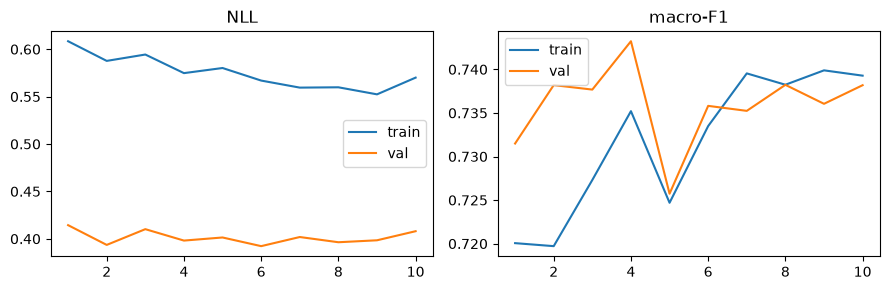

{'model': 'gru', 'lookback': 14, 'horizon': 1, 'hidden': 64, 'd_model': 64, 'layers': 2, 'dropout': 0.2, 'heads': 2, 'lr': 0.001, 'batch_size': 128, 'optimizer': 'adamw', 'weight_decay': 0.0, 'loss': 'wce', 'focal_gamma': 2.0, 'epochs': 40, 'patience': 6, 'seed': 42, 'modalities': ['climate', 'air', 'dryness'], 'use_context': True, 'fusion': 'attention', 'encoder': 'gru', 'air_encoder': 'gru', 'dry_encoder': 'gru', 'token_self_attention': True, 'modality_dropout': 0.1, 'drop_features': [], 'max_missing': 3, 'train_sites': None, 'grad_clip': 1.0}


In [6]:
# learning curves of the best-validation GRU seed
ids = fs["gru"]["run_ids"]; recs = [read_json(ROOT / "experiments/final" / f"{r}.json") for r in ids]
r = max(recs, key=lambda r: r["val_metrics"]["macro_f1"]); h = pd.DataFrame(r["history"])
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(h.epoch, h.train_nll, label="train"); ax[0].plot(h.epoch, h.val_nll, label="val"); ax[0].set_title("NLL"); ax[0].legend()
ax[1].plot(h.epoch, h.train_macro_f1, label="train"); ax[1].plot(h.epoch, h.val_macro_f1, label="val"); ax[1].set_title("macro-F1"); ax[1].legend()
plt.tight_layout(); plt.show(); print(r["config"])